# Домашнее задание 3.3: Фракталы как вычислительный эксперимент (🟢)

Отображение $z_{n+1} = z_n^2 + c$.

| множество | что меняется | что фиксировано | радиус ухода $R$ |
|---|---|---|---|
| Мандельброта $M$ | параметр $c$ | $z_0 = 0$ | $2$ |
| заполненное Джулиа $K_c$ | начальная точка $z_0$ | параметр $c$ | $\max(2, \lvert c\rvert)$ |

Точка ушла на итерации $n$, если на ней впервые выполнилось строгое $|z_n| > R$.
Сетка $600\times600$, $N_{\max} = 200$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, ListedColormap

plt.rcParams["figure.dpi"] = 110

## 1. Время ухода и булева маска

В массиве `active` отмечены точки, которые ещё не ушли, и на каждой итерации обновляются только
они. Как только у точки $|z| > R$, она получает номер итерации ухода и выбывает из маски —
больше её значение не меняется. Точки, которые не ушли за $N_{\max}$ итераций, помечаются $-1$.

Почему такой критерий корректен: если $|z| > R \ge \max(2, |c|)$, то
$|z^2 + c| \ge |z|^2 - |c| > |z|(|z| - 1) > |z|$, причём $|z| - 1 > 1$. Значит, дальше модуль
растёт не медленнее геометрической прогрессии, и орбита уходит на бесконечность.

In [2]:
def grid(re_min, re_max, im_min, im_max, n):
    re = np.linspace(re_min, re_max, n)
    im = np.linspace(im_min, im_max, n)
    return re[None, :] + 1j * im[:, None]


def escape_time(z0, c, R, n_max):
    z = np.array(z0, dtype=complex)
    c = np.broadcast_to(np.asarray(c, dtype=complex), z.shape).copy()
    n_esc = np.full(z.shape, -1, dtype=int)
    active = np.ones(z.shape, dtype=bool)

    esc = np.abs(z) > R               # точки, лежащие вне круга радиуса R уже при n = 0
    n_esc[esc] = 0
    active &= ~esc
    for n in range(1, n_max + 1):
        z[active] = z[active] ** 2 + c[active]
        esc = active & (np.abs(z) > R)
        n_esc[esc] = n
        active &= ~esc
        if not active.any():
            break
    return n_esc


def show_escape(ax, n_esc, extent, n_max, title):
    cmap = ListedColormap(plt.get_cmap("magma")(np.linspace(0.3, 1.0, 256)))
    cmap.set_bad("black")   # невышедшие точки — чёрный, вне шкалы ушедших точек
    data = np.ma.masked_where(n_esc < 0, n_esc.astype(float) + 1)
    im = ax.imshow(data, extent=extent, origin="lower", cmap=cmap,
                   norm=LogNorm(vmin=1, vmax=n_max + 1), interpolation="nearest")
    ax.set_aspect("equal")
    ax.set_xlabel("Re"); ax.set_ylabel("Im")
    ax.set_title(title, fontsize=10)
    return im

## 2. Множество Мандельброта

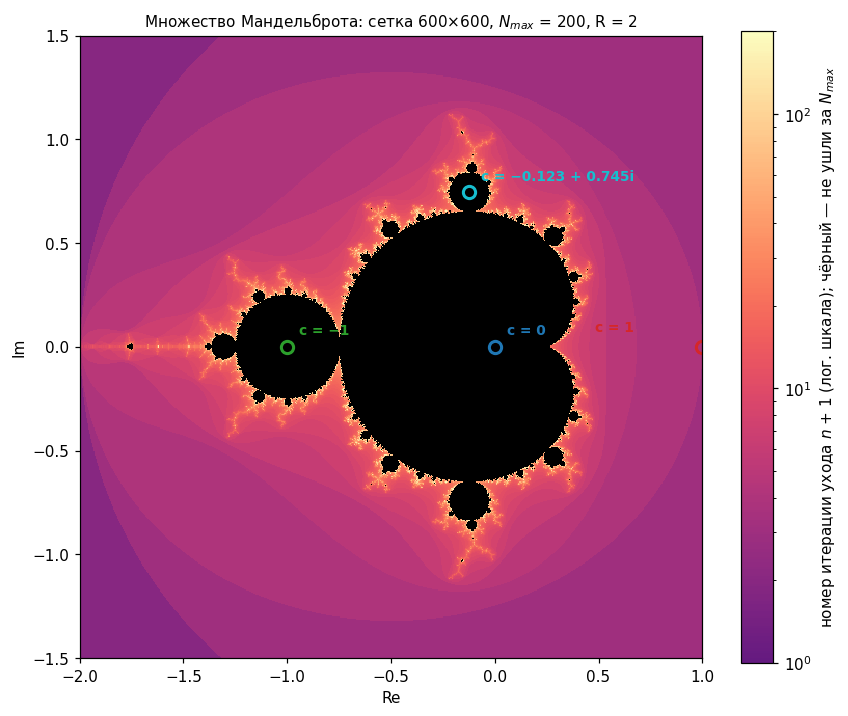

доля невышедших точек: 0.1689; оценка площади M: 1.5252


In [3]:
N, N_MAX = 600, 200
ext_M = (-2.0, 1.0, -1.5, 1.5)
C = grid(*ext_M, N)
nM = escape_time(np.zeros_like(C), C, 2.0, N_MAX)

c_list = [0.0 + 0.0j, -1.0 + 0.0j, -0.123 + 0.745j, 1.0 + 0.0j]
c_names = ["c = 0", "c = −1", "c = −0.123 + 0.745i", "c = 1"]

fig, ax = plt.subplots(figsize=(8, 7.5))
im = show_escape(ax, nM, ext_M, N_MAX,
                 f"Множество Мандельброта: сетка {N}×{N}, $N_{{max}}$ = {N_MAX}, R = 2")
for cc, nm, col in zip(c_list, c_names, ["C0", "C2", "C9", "C3"]):
    ax.plot(cc.real, cc.imag, "o", ms=8, mfc="none", mec=col, mew=2)
    ax.annotate(nm, (cc.real, cc.imag), xytext=(-70, 10) if cc.real > 0.5 else (8, 8), textcoords="offset points",
                color=col, fontsize=9, fontweight="bold")
cb = fig.colorbar(im, ax=ax, shrink=0.8)
cb.set_label("номер итерации ухода $n$ + 1 (лог. шкала); чёрный — не ушли за $N_{max}$")
fig.tight_layout()
plt.show()

frac_M = (nM < 0).mean()
pixel_area = (3.0 / (N - 1)) ** 2
print(f"доля невышедших точек: {frac_M:.4f}; оценка площади M: {(nM < 0).sum() * pixel_area:.4f}")

## 3. Заполненные множества Джулиа

Область $[-2, 2] \times [-2, 2]$, радиус ухода $R = \max(2, |c|)$.

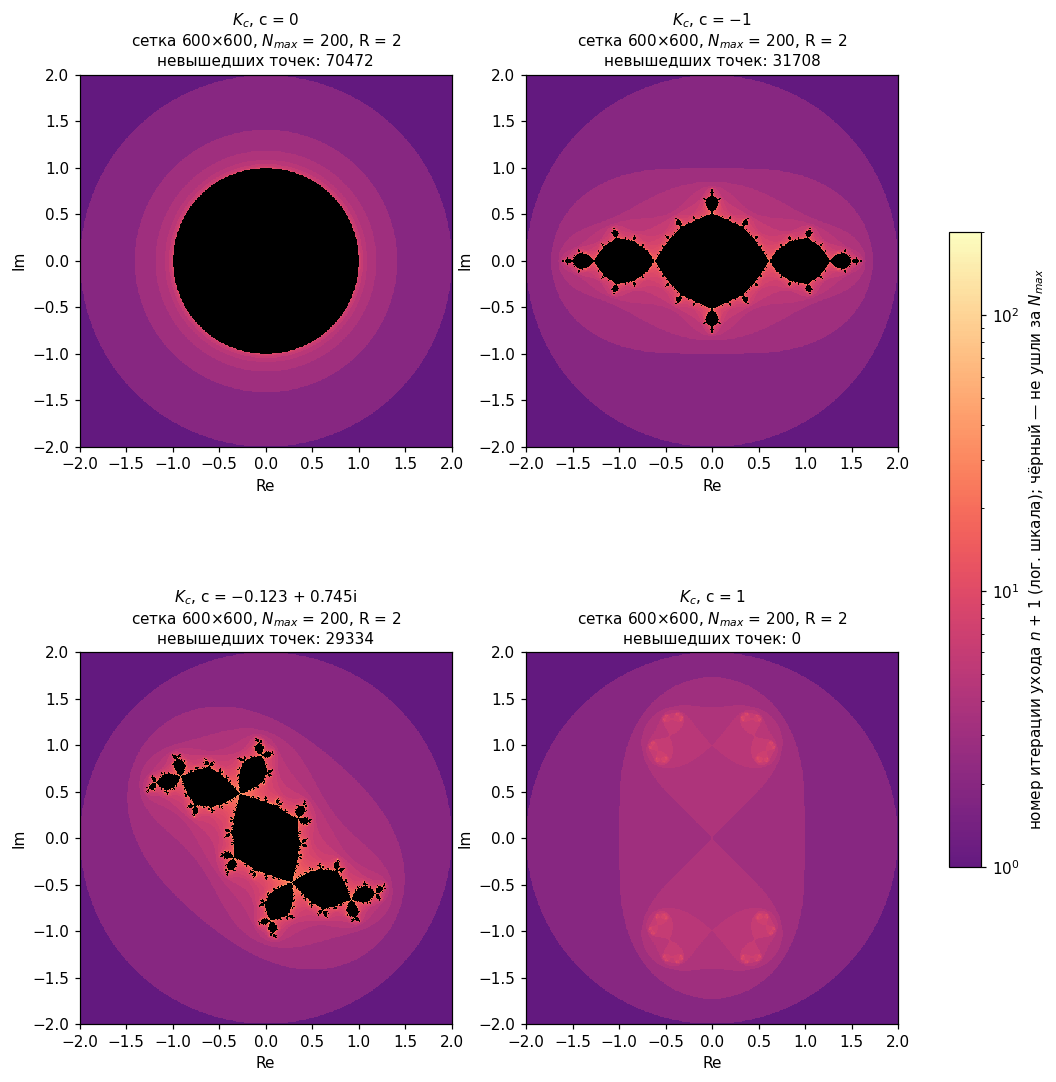

In [4]:
ext_J = (-2.0, 2.0, -2.0, 2.0)
Z0 = grid(*ext_J, N)
julia = {}
for cc in c_list:
    R = max(2.0, abs(cc))
    julia[cc] = escape_time(Z0, cc, R, N_MAX)

fig, axes = plt.subplots(2, 2, figsize=(12, 12.5))
for ax, cc, nm in zip(axes.ravel(), c_list, c_names):
    nJ = julia[cc]
    im = show_escape(ax, nJ, ext_J, N_MAX,
                     f"$K_c$, {nm}\nсетка {N}×{N}, $N_{{max}}$ = {N_MAX}, R = {max(2.0, abs(cc)):g}\n"
                     f"невышедших точек: {(nJ < 0).sum()}")
fig.colorbar(im, ax=axes, shrink=0.6,
             label="номер итерации ухода $n$ + 1 (лог. шкала); чёрный — не ушли за $N_{max}$")
plt.show()

Что видно на картинках:

| $c$ | где лежит относительно $M$ | как выглядит $K_c$ |
|---|---|---|
| $0$ | центр главной кардиоиды | единичный круг |
| $-1$ | центр круга периода 2 | связное множество («базилика»), притягивающий цикл периода 2 |
| $-0.123 + 0.745i$ | внутри компоненты периода 3 | связное множество («кролик Дуади»), притягивающий цикл периода 3 |
| $1$ | вне $M$ | канторова пыль: внутренности нет, на сетке уходят все точки |

## 4. Случай $c = 0$: сравнение с единичным кругом

При $c = 0$ орбита $z_n = z_0^{2^n}$, так что $K_0$ — замкнутый единичный круг, а $J_0$ —
единичная окружность. Точка с $|z_0| = r > 1$ уходит на итерации
$n(r) = \lfloor\log_2(\ln 2 / \ln r)\rfloor + 1$ — первой, на которой $r^{2^n} > 2$.

In [5]:
nJ0 = julia[0j]
r = np.abs(Z0)
inside_disk = r <= 1.0
not_escaped = nJ0 < 0
mismatch_in = np.sum(inside_disk & ~not_escaped)
mismatch_out = np.sum(~inside_disk & not_escaped)
print(f"точек сетки в единичном круге: {inside_disk.sum()}, невышедших точек: {not_escaped.sum()}")
print(f"точек круга, ушедших за N_max: {mismatch_in}; точек вне круга, не ушедших: {mismatch_out}")

with np.errstate(divide="ignore", invalid="ignore"):
    n_theory = np.where(r > 1, np.floor(np.log2(np.log(2) / np.log(r))) + 1, -1)
n_theory = np.where(r > 2, 0, n_theory)
print(f"совпадение номера итерации ухода с формулой n(r): "
      f"{np.mean(n_theory[~inside_disk] == nJ0[~inside_disk]) * 100:.2f}% точек вне круга")

точек сетки в единичном круге: 70472, невышедших точек: 70472
точек круга, ушедших за N_max: 0; точек вне круга, не ушедших: 0
совпадение номера итерации ухода с формулой n(r): 100.00% точек вне круга


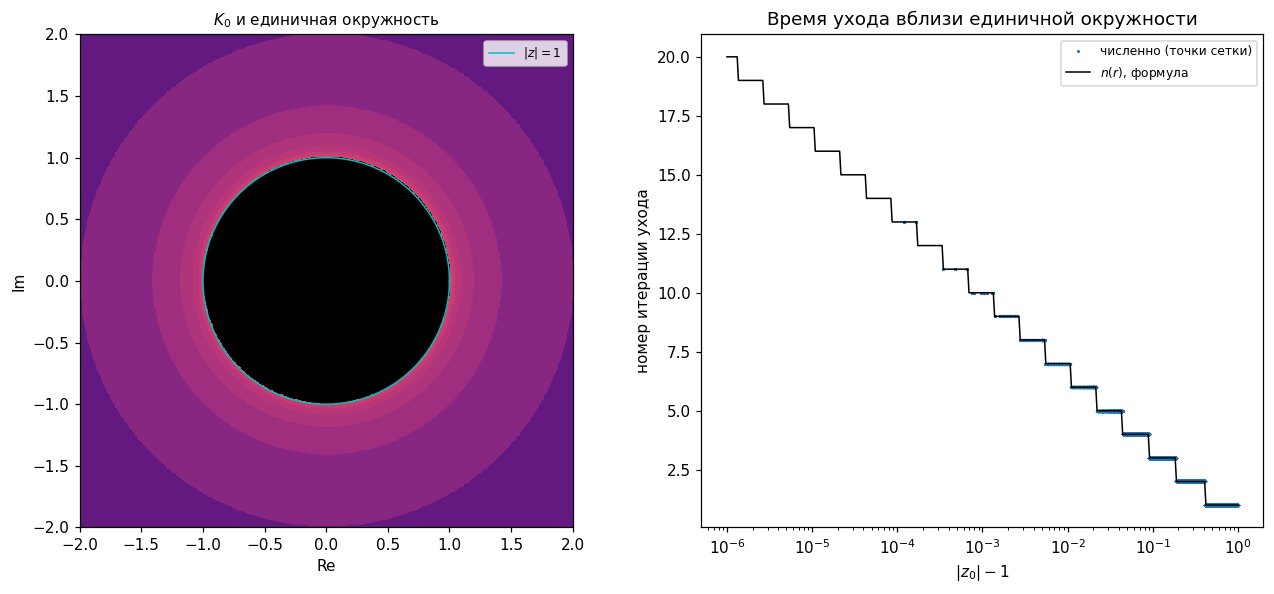

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
show_escape(axes[0], nJ0, ext_J, N_MAX, "$K_0$ и единичная окружность")
phi = np.linspace(0, 2 * np.pi, 400)
axes[0].plot(np.cos(phi), np.sin(phi), "c-", lw=1, label="$|z| = 1$")
axes[0].legend(loc="upper right", fontsize=8)

sel = (r > 1) & (r < 2)
axes[1].semilogx(r[sel] - 1, nJ0[sel], "C0.", ms=2, label="численно (точки сетки)")
rr = np.logspace(-6, np.log10(1), 400) + 1
axes[1].semilogx(rr - 1, np.floor(np.log2(np.log(2) / np.log(rr))) + 1, "k-", lw=1, label="$n(r)$, формула")
axes[1].set_xlabel("$|z_0| - 1$"); axes[1].set_ylabel("номер итерации ухода")
axes[1].set_title("Время ухода вблизи единичной окружности")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

Невышедшие точки сетки — ровно те, что лежат в замкнутом единичном круге. Время ухода
растёт логарифмически при приближении к окружности снаружи: даже при $|z_0| - 1 = 10^{-6}$
нужно всего около 20 итераций, поэтому при $N_{\max} = 200$ уходят все точки сетки вне круга.
Граница $J_0$ на картинке проходит между чёрной областью и пикселями с самыми большими
номерами ухода.

## 5. Ответ на вопрос

**Что можно утверждать о точке, которая не вышла за радиус за конечное число шагов?**

1. Только то, что $|z_n| \le R$ для $n = 0, \dots, N_{\max}$. Что точка лежит в $K_c$ или в
   $M$, отсюда не следует. Точка вне множества, но рядом с его границей уходит тем дольше, чем
   ближе она к границе, и это время ничем не ограничено (при $c = 0$ оно растёт как
   $\log_2(1/(|z_0| - 1))$). Невышедшие точки приближают множество с избытком и при
   $N_{\max} \to \infty$ сходятся к нему.
2. В обратную сторону вывод строгий: точка, вышедшая за $R \ge \max(2, |c|)$, множеству точно
   не принадлежит (доказательство в разделе 1).
3. Каждая точка сетки — одна выборка на пиксель. Чёрный пиксель значит, что не ушёл его центр,
   а не весь пиксель. Детали тоньше шага сетки — тонкие перешейки $M$, канторова пыль $K_1$ —
   на картинку не попадают. Например, $K_1$ не пусто (в нём есть отталкивающие неподвижные
   точки $z = (1 \pm i\sqrt3)/2$), но площадь у него нулевая, и ни одна точка сетки в него не
   попадает.